<a href="https://colab.research.google.com/github/Starleen1996/analisis_datos_curso/blob/main/analitica_datos_11_11_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**PRIMER PASO**

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Colores: uno de resalte y uno neutro
COLOR_RESALTE = "#1f6feb"
COLOR_BASE = "#b8c4d6"

# Estilo limpio para todos los gráficos
plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

def en_pesos(valor):
    """Escribe un número como valor en pesos, por ejemplo $1,250,000."""
    return f"${valor:,.0f}"

print("Entorno listo")

Entorno listo


**SEGUNDO PASO**

In [9]:
import pandas as pd
import numpy as np

# Configurar la semilla para reproducibilidad
np.random.seed(42)

# Definir el tamaño base de la muestra
n_registros = 1000

# Generar fechas aleatorias dentro del año 2026
fechas = pd.to_datetime('2026-01-01') + pd.to_timedelta(np.random.randint(0, 365, size=n_registros), unit='D')

# Opciones para las variables categóricas
sucursales = ['Norte', 'Centro', 'Sur']
categorias = ['Bebidas', 'Snacks', 'Papelería', 'Hogar']
canales = ['Tienda', 'En línea']

# Crear el DataFrame inicial
df = pd.DataFrame({
    'fecha': fechas,
    'sucursal': np.random.choice(sucursales, size=n_registros),
    'categoria': np.random.choice(categorias, size=n_registros),
    'canal': np.random.choice(canales, size=n_registros),
    'unidades': np.random.randint(1, 15, size=n_registros).astype(float),
    'precio_unitario': np.random.uniform(50.0, 500.0, size=n_registros)
})

# 1. Introducir 40 valores vacíos (NaN) en la columna 'unidades'
indices_nan = np.random.choice(df.index, size=40, replace=False)
df.loc[indices_nan, 'unidades'] = np.nan

# 2. Agregar 15 filas repetidas seleccionadas al azar de los datos generados
indices_repetidos = np.random.choice(df.index, size=15, replace=True)
filas_repetidas = df.loc[indices_repetidos]
df = pd.concat([df, filas_repetidas], ignore_index=True)

# Calcular el total para tener la estructura base inicial
df['total_ventas'] = df['unidades'] * df['precio_unitario']

# Mostrar el resumen y las primeras filas
print(f"Filas totales (incluyendo repetidas): {len(df)}")
print(f"Valores nulos en unidades: {df['unidades'].isnull().sum()}")
print(f"Cantidad de filas duplicadas: {df.duplicated().sum()}")
display(df.head(120))


Filas totales (incluyendo repetidas): 1015
Valores nulos en unidades: 40
Cantidad de filas duplicadas: 15


,fecha,sucursal,categoria,canal,unidades,precio_unitario,total_ventas
0,2026-04-13,Sur,Hogar,Tienda,4.0,391.581023,1566.324091
1,2026-12-15,Sur,Hogar,Tienda,6.0,324.333955,1946.003731
2,2026-09-28,Norte,Snacks,En línea,11.0,453.218360,4985.401958
3,2026-04-17,Centro,Papelería,Tienda,5.0,418.112037,2090.560186
4,2026-03-13,Centro,Snacks,Tienda,2.0,163.766123,327.532245
...,...,...,...,...,...,...,...
115,2026-02-17,Sur,Hogar,Tienda,11.0,320.496213,3525.458343
116,2026-03-03,Norte,Snacks,Tienda,10.0,495.662802,4956.628019
117,2026-08-04,Norte,Snacks,En línea,3.0,196.364258,589.092773
118,2026-10-20,Norte,Snacks,En línea,2.0,473.572602,947.145203


In [10]:
df.describe()

,fecha,unidades,precio_unitario,total_ventas
count,1015,975.000000,1015.000000,975.000000
mean,2026-07-01 19:46:02.955665152,7.452308,279.982975,2056.841053
min,2026-01-01 00:00:00,1.000000,50.908333,59.302116
25%,2026-04-08 00:00:00,4.000000,172.131022,784.217897
50%,2026-07-01 00:00:00,7.000000,284.719728,1649.424527
75%,2026-09-28 00:00:00,11.000000,391.039641,3021.188596
max,2026-12-31 00:00:00,14.000000,499.794763,6997.126688
std,NaN,3.996345,127.827001,1532.951949


### **TERCER PASO: Limpieza de Datos (Duplicados y Nulos)**

Aplicaremos la estrategia definida:
1. Eliminar las 15 filas duplicadas.
2. Imputar los valores nulos en la columna `unidades` con la mediana entera.
3. Recalcular la columna dependiente `total_ventas` para los registros modificados.

In [11]:
# 1. Eliminar filas duplicadas
df_limpio = df.drop_duplicates().copy()
print(f"Filas después de eliminar duplicados: {len(df_limpio)} (Se eliminaron {len(df) - len(df_limpio)} filas)")

# 2. Calcular la mediana de la columna 'unidades' (entera)
mediana_unidades = int(df_limpio['unidades'].median())
print(f"La mediana calculada para 'unidades' es: {mediana_unidades}")

# Imputar los valores nulos con la mediana
df_limpio['unidades'] = df_limpio['unidades'].fillna(mediana_unidades)

# 3. Recalcular 'total_ventas' para asegurar consistencia matemática
df_limpio['total_ventas'] = df_limpio['unidades'] * df_limpio['precio_unitario']

# Verificar que no queden valores nulos ni duplicados
print(f"Valores nulos restantes en 'unidades': {df_limpio['unidades'].isnull().sum()}")
print(f"Filas duplicadas restantes: {df_limpio.duplicated().sum()}")

display(df_limpio.info())


Filas después de eliminar duplicados: 1000 (Se eliminaron 15 filas)
La mediana calculada para 'unidades' es: 7
Valores nulos restantes en 'unidades': 0
Filas duplicadas restantes: 0
<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   fecha            1000 non-null   datetime64[ns]
 1   sucursal         1000 non-null   object        
 2   categoria        1000 non-null   object        
 3   canal            1000 non-null   object        
 4   unidades         1000 non-null   float64       
 5   precio_unitario  1000 non-null   float64       
 6   total_ventas     1000 non-null   float64       
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 62.5+ KB


None

**CREACIÓN DE NUEVAS COLUMNAS**
Nota: La creación de nuevas columnas se deben crear, una vez se realiza la creación del dataset.

In [12]:
# Para el cálculo de ingresos requerimos una columna de 'descuento'
# Generamos descuentos aleatorios de manera realista (por ejemplo: 0%, 5%, 10% o 15%)
np.random.seed(42)  # Mantener reproducibilidad
opciones_descuento = [0.0, 0.05, 0.10, 0.15]
df_limpio['descuento'] = np.random.choice(opciones_descuento, size=len(df_limpio), p=[0.5, 0.2, 0.2, 0.1])

# Crear las columnas solicitadas por el usuario
df_limpio["ingreso"] = df_limpio["unidades"] * df_limpio["precio_unitario"] * (1 - df_limpio["descuento"])
df_limpio["mes"] = df_limpio["fecha"].dt.to_period("M").astype(str)
df_limpio["trimestre"] = df_limpio["fecha"].dt.quarter

# Mostrar el resultado final
display(df_limpio.head())

,fecha,sucursal,categoria,canal,unidades,precio_unitario,total_ventas,descuento,ingreso,mes,trimestre
0,2026-04-13,Sur,Hogar,Tienda,4.0,391.581023,1566.324091,0.00,1566.324091,2026-04,2
1,2026-12-15,Sur,Hogar,Tienda,6.0,324.333955,1946.003731,0.15,1654.103172,2026-12,4
2,2026-09-28,Norte,Snacks,En línea,11.0,453.218360,4985.401958,0.10,4486.861762,2026-09,3
3,2026-04-17,Centro,Papelería,Tienda,5.0,418.112037,2090.560186,0.05,1986.032176,2026-04,2
4,2026-03-13,Centro,Snacks,Tienda,2.0,163.766123,327.532245,0.00,327.532245,2026-03,1


### **CUARTO PASO: Visualización de Línea de Tiempo de Ingreso Mensual**

Agruparemos el DataFrame por la columna `mes` para sumar los ingresos totales de cada mes y graficaremos la tendencia mensual.

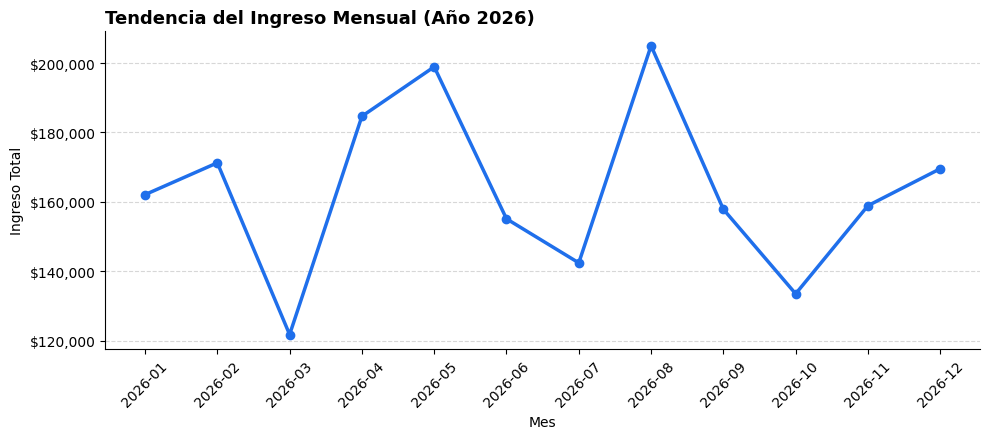

In [13]:
# Agrupar los ingresos por mes
ingreso_mensual = df_limpio.groupby('mes')['ingreso'].sum().reset_index()

# Crear el gráfico de línea
plt.figure(figsize=(10, 4.5))
plt.plot(ingreso_mensual['mes'], ingreso_mensual['ingreso'], marker='o', color=COLOR_RESALTE, linewidth=2.5)

# Personalizar el gráfico
plt.title("Tendencia del Ingreso Mensual (Año 2026)")
plt.xlabel("Mes")
plt.ylabel("Ingreso Total")
plt.xticks(rotation=45)

# Aplicar el formato de pesos en el eje Y
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: en_pesos(x)))

# Añadir cuadrícula sutil en el eje Y
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### **QUINTO PASO: Comparación de Ingresos por Sucursal y Categoría**

Agruparemos el ingreso total acumulado por cada combinación de `sucursal` y `categoria` para visualizar la comparativa mediante un gráfico de barras agrupadas.

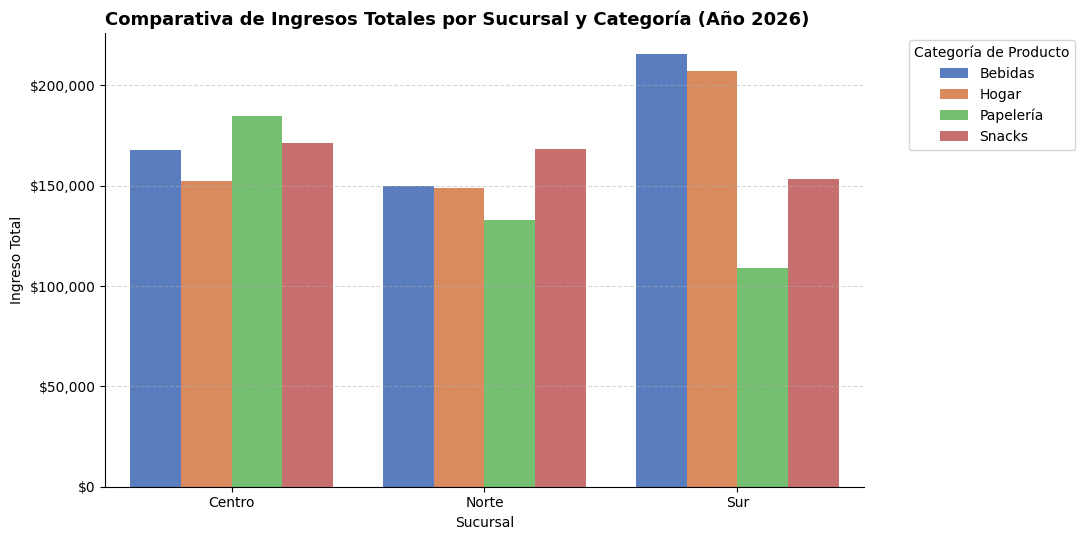

In [14]:
# Agrupar los ingresos por sucursal y categoría
ingreso_grupos = df_limpio.groupby(['sucursal', 'categoria'])['ingreso'].sum().reset_index()

# Crear el gráfico de barras agrupadas
plt.figure(figsize=(11, 5.5))
sns.barplot(
    data=ingreso_grupos,
    x='sucursal',
    y='ingreso',
    hue='categoria',
    palette='muted'  # Usamos una paleta de colores clara y distinguible
)

# Personalizar el gráfico
plt.title("Comparativa de Ingresos Totales por Sucursal y Categoría (Año 2026)")
plt.xlabel("Sucursal")
plt.ylabel("Ingreso Total")

# Aplicar formato de pesos al eje Y
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: en_pesos(x)))

# Ajustes de estilo adicionales
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Categoría de Producto", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### **SEXTO PASO: Comparación de Ingresos por Sucursal y Canal de Ventas**

Agruparemos el ingreso total por cada combinación de `sucursal` y `canal` de ventas, y utilizaremos un gráfico de barras agrupadas para identificar el canal dominante por zona.

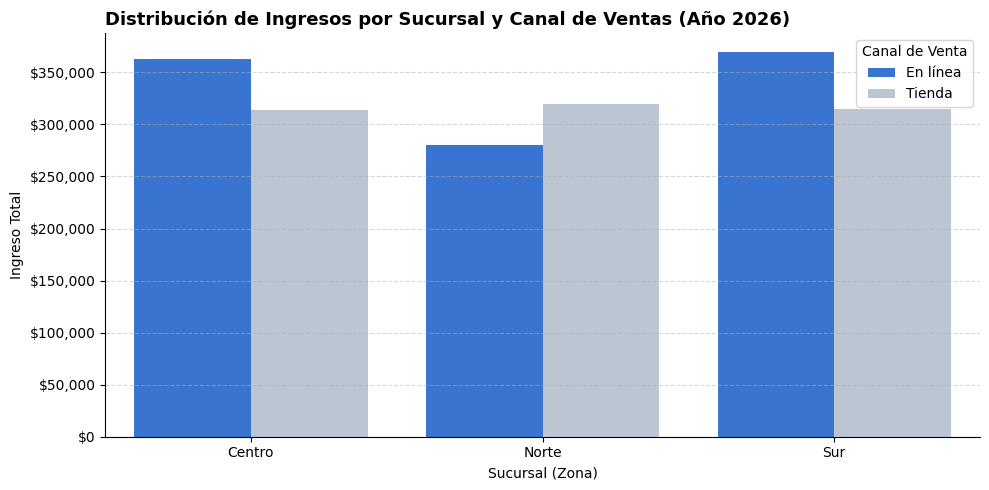

In [15]:
# Agrupar los ingresos por sucursal y canal de ventas
ingreso_canal = df_limpio.groupby(['sucursal', 'canal'])['ingreso'].sum().reset_index()

# Crear el gráfico de barras agrupadas
plt.figure(figsize=(10, 5))
sns.barplot(
    data=ingreso_canal,
    x='sucursal',
    y='ingreso',
    hue='canal',
    palette=[COLOR_RESALTE, COLOR_BASE]  # Usamos nuestra paleta institucional definida en el setup
)

# Personalizar el gráfico
plt.title("Distribución de Ingresos por Sucursal y Canal de Ventas (Año 2026)")
plt.xlabel("Sucursal (Zona)")
plt.ylabel("Ingreso Total")

# Aplicar formato de pesos al eje Y
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: en_pesos(x)))

# Ajustes de diseño
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Canal de Venta", loc='upper right')
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### **SÉPTIMO PASO: Mapa de Calor de Ingresos (en Millones) por Zona y Categoría**

Crearemos una matriz pivotada que cruce las sucursales con las categorías de productos, convirtiendo los ingresos a escala de millones de pesos para representarlos visualmente con un mapa de calor (`sns.heatmap`).

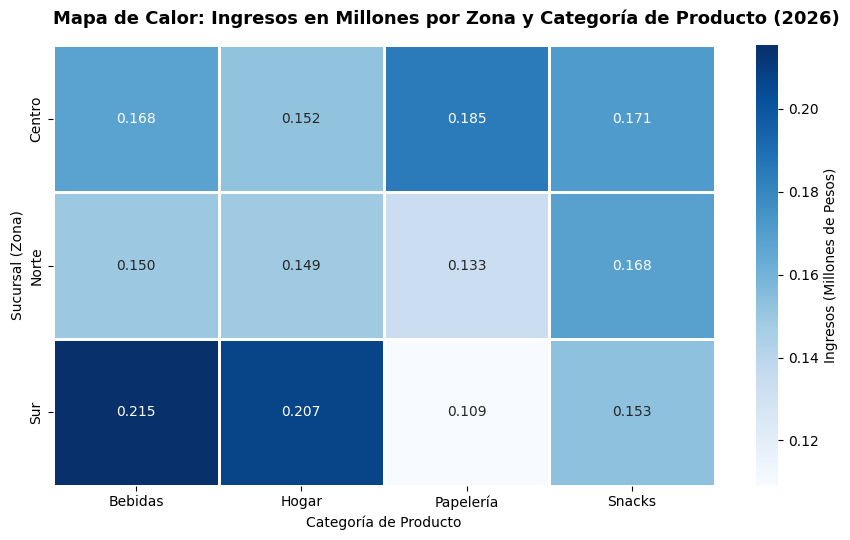

In [16]:
# 1. Crear la matriz pivotada de ingresos por sucursal y categoría
matriz_ingresos = df_limpio.pivot_table(
    index='sucursal',
    columns='categoria',
    values='ingreso',
    aggfunc='sum'
)

# 2. Convertir los valores a millones de pesos (dividir entre 1,000,000)
matriz_ingresos_millones = matriz_ingresos / 1_000_000

# 3. Dibujar el mapa de calor
plt.figure(figsize=(9, 5.5))
sns.heatmap(
    matriz_ingresos_millones,
    annot=True,             # Mostrar los valores numéricos dentro de las celdas
    fmt=".3f",              # Formato con 3 decimales para ver el detalle de los millones
    cmap="Blues",           # Usar gama de azules consistente con el color institucional
    linewidths=0.8,         # Línea divisoria sutil entre celdas
    cbar_kws={'label': 'Ingresos (Millones de Pesos)'} # Etiqueta de la barra de color
)

# Personalizar el gráfico
plt.title("Mapa de Calor: Ingresos en Millones por Zona y Categoría de Producto (2026)", pad=15)
plt.xlabel("Categoría de Producto")
plt.ylabel("Sucursal (Zona)")

plt.tight_layout()
plt.show()

### **OCTAVO PASO: Diagrama Circular de Proporción de Ingresos por Regional (Sucursal)**

Agruparemos el total de ingresos por `sucursal` y generaremos un gráfico circular para visualizar de forma clara el porcentaje de contribución de cada zona al total de la empresa.

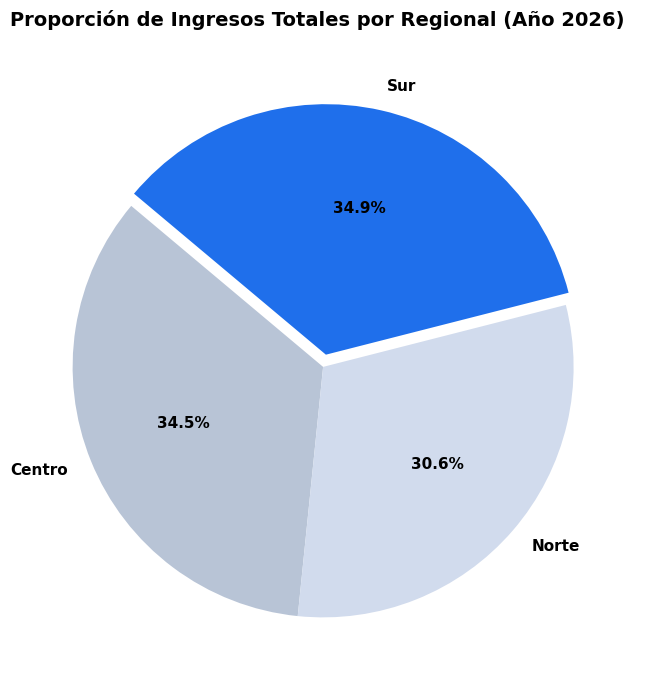

In [17]:
# 1. Agrupar ingresos por sucursal
ingresos_regionales = df_limpio.groupby('sucursal')['ingreso'].sum().reset_index()

# 2. Configurar el diseño del gráfico circular
plt.figure(figsize=(7, 7))
colores_pastel = [COLOR_BASE, '#d1dbed', COLOR_RESALTE] # Resaltamos la regional con más ventas

# Crear el gráfico de pastel
plt.pie(
    ingresos_regionales['ingreso'],
    labels=ingresos_regionales['sucursal'],
    autopct='%1.1f%%',          # Mostrar porcentaje con un decimal
    startangle=140,             # Ángulo de inicio para una mejor orientación
    colors=colores_pastel,     # Paleta de colores institucional
    explode=(0, 0, 0.05),       # Resaltar sutilmente la rebanada de la regional que más vende (Sur)
    textprops={'fontsize': 11, 'weight': 'bold'}
)

# Personalizar el gráfico
plt.title("Proporción de Ingresos Totales por Regional (Año 2026)", pad=20, fontsize=14)

# Mostrar el gráfico
plt.tight_layout()
plt.show()

```markdown
# **INFORME ESTRATÉGICO DE VENTAS - CONCLUSIONES Y RECOMENDACIONES (AÑO 2026)**

Este informe consolida los hallazgos clave derivados del análisis de datos de ventas de las tres regionales (Centro, Norte y Sur). El objetivo es proveer a la directiva una hoja de ruta clara para la optimización de recursos, inventarios y campañas de marketing para el próximo periodo.

---

## **1. Conclusiones Clave del Desempeño General**

* **Equilibrio de Mercado:** El negocio tiene una distribución de ingresos notablemente balanceada entre sus tres regionales. La **Regional Sur** lidera ligeramente con el **34.9%** de participación de ingresos, seguida de cerca por la **Regional Centro** con el **34.5%** y la **Regional Norte** con el **30.6%**.
* **Comportamiento Estacional (Temporalidad):** Se identificó un patrón de alta volatilidad mensual. **Agosto** se consagró como el mes de mayores ingresos históricos del año (superando los **$204,000**), mientras que **Marzo** representó el valle de ventas más bajo (aproximadamente **$121,000**).
* **La Fuerza de los Canales Digitales:** El canal **En línea** es el principal motor de ventas en el **Sur** (~$369.4k) y en el **Centro** (~$362.4k), evidenciando que la madurez digital es clave para sostener las operaciones más rentables.

---

## **2. Estrategia y Recomendaciones de Productos por Regional**

Para maximizar el retorno de inversión (ROI), se sugiere personalizar la mezcla de productos y promociones de acuerdo al ADN de compra de cada zona:

### **A. Regional Sur: El Corazón del Consumo Masivo**
* **Diagnóstico:** Registra los ingresos más altos de toda la empresa pero también la debilidad más severa.
* **Acciones Estratégicas:**
  * **Sostener el Liderazgo (Bebidas y Hogar):** Mantener un inventario prioritario y robusto en *Bebidas* (que aporta el máximo histórico de **$0.215M**) e *Hogar* (**$0.207M**). Evitar roturas de stock en esta zona es crítico.
  * **Plan de Choque para Papelería:** Es el producto menos vendido del portafolio global (**$0.109M**). Se recomienda reevaluar el catálogo local o discontinuar líneas de baja rotación, canalizando el esfuerzo publicitario únicamente a ofertas de temporada (ej. regreso a clases).

### **B. Regional Centro: El Fortín de la Papelería**
* **Diagnóstico:** Zona sumamente sólida con excelente recepción en productos corporativos y de oficina.
* **Acciones Estratégicas:**
  * **Fidelizar el Sector Papelería:** Es la categoría estrella de esta región (**$0.185M**). Se sugiere crear paquetes de venta cruzada (bundles) de *Papelería* combinados con *Snacks* para el mercado corporativo.
  * **Impulsar Hogar:** Es el punto débil relativo en el Centro (**$0.152M**). Introducir promociones exclusivas en la plataforma de compras *En línea* podría incentivar este sector.

### **C. Regional Norte: El Baluarte Tradicional**
* **Diagnóstico:** Es la única zona donde el canal físico (**Tienda**) supera de forma contundente al canal digital, impulsada fuertemente por la categoría de Snacks.
* **Acciones Estratégicas:**
  * **Fortalecer la Experiencia en Tienda Física:** Dado que el canal físico factura más de **$319k**, se deben destinar esfuerzos a mejorar el visual merchandising, especialmente en la categoría de **Snacks** (**$0.168M**).
  * **Transformación Digital Sutil:** Crear incentivos como "descuentos exclusivos en línea con retiro en tienda (Click & Collect)" para migrar progresivamente a los clientes físicos al canal digital y optimizar costos operativos.

---

## **3. Lineamientos de Planificación y Presupuesto**

1. **Campañas de Marketing Estacionales:** Direccionar la mayor parte del presupuesto publicitario anual hacia el trimestre previo al pico de **Agosto** (Mayo - Julio) para capitalizar la alta intención de compra, y planificar campañas agresivas de retención o liquidación durante **Marzo y Octubre** para suavizar las caídas estacionales.
2. **Logística Predictiva:** Ajustar las órdenes de compra de inventario basándose en las matrices de calor para evitar costos de almacenamiento excesivos en categorías lentas (como Papelería en el Sur) y asegurar la liquidez del capital de trabajo.
```

### **NOVENO PASO: Exportación del Informe Técnico a PDF y Gráficos a Imágenes PNG**

En esta celda instalaremos la librería necesaria para construir PDFs en Python (`reportlab`), guardaremos todos los gráficos visualizados anteriormente como archivos de imagen de alta resolución en el sistema de archivos local y compilaremos el documento final `Informe_Ventas_Regionales_2026.pdf`.

In [18]:
!pip install -q reportlab

In [19]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from reportlab.lib.pagesizes import letter
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle, PageBreak
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle

# --- 1. GUARDAR GRÁFICOS COMO IMÁGENES DE ALTA RESOLUCIÓN ---
os.makedirs("graficos_reporte", exist_ok=True)

# Gráfico 1: Tendencia Mensual
plt.figure(figsize=(10, 4))
plt.plot(ingreso_mensual['mes'], ingreso_mensual['ingreso'], marker='o', color=COLOR_RESALTE, linewidth=2.5)
plt.title("Tendencia del Ingreso Mensual (Año 2026)")
plt.xlabel("Mes")
plt.ylabel("Ingreso Total")
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: en_pesos(x)))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("graficos_reporte/01_tendencia_mensual.png", dpi=300)
plt.close()

# Gráfico 2: Comparativa por Categoría y Sucursal
plt.figure(figsize=(10, 4.5))
sns.barplot(data=ingreso_grupos, x='sucursal', y='ingreso', hue='categoria', palette='muted')
plt.title("Comparativa de Ingresos Totales por Sucursal y Categoría")
plt.xlabel("Sucursal")
plt.ylabel("Ingreso Total")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: en_pesos(x)))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Categoría", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig("graficos_reporte/02_sucursal_categoria.png", dpi=300)
plt.close()

# Gráfico 3: Ventas por Canal
plt.figure(figsize=(10, 4))
sns.barplot(data=ingreso_canal, x='sucursal', y='ingreso', hue='canal', palette=[COLOR_RESALTE, COLOR_BASE])
plt.title("Distribución de Ingresos por Sucursal y Canal de Ventas")
plt.xlabel("Sucursal")
plt.ylabel("Ingreso Total")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: en_pesos(x)))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Canal de Venta")
plt.tight_layout()
plt.savefig("graficos_reporte/03_sucursal_canal.png", dpi=300)
plt.close()

# Gráfico 4: Mapa de Calor
plt.figure(figsize=(8, 4.5))
sns.heatmap(matriz_ingresos_millones, annot=True, fmt=".3f", cmap="Blues", linewidths=0.8, cbar_kws={'label': 'Ingresos (M$)'})
plt.title("Mapa de Calor: Ingresos en Millones por Zona y Categoría", pad=10)
plt.xlabel("Categoría")
plt.ylabel("Sucursal")
plt.tight_layout()
plt.savefig("graficos_reporte/04_mapa_calor.png", dpi=300)
plt.close()

print("Gráficos exportados con éxito a la carpeta 'graficos_reporte/'")

Gráficos exportados con éxito a la carpeta 'graficos_reporte/'


In [20]:
# --- 2. CONSTRUCCIÓN DEL DOCUMENTO PDF ---
pdf_filename = "Informe_Ventas_Regionales_2026.pdf"
doc = SimpleDocTemplate(pdf_filename, pagesize=letter,
                        rightMargin=40, leftMargin=40, topMargin=40, bottomMargin=40)

styles = getSampleStyleSheet()

# Estilos personalizados de texto
title_style = ParagraphStyle(
    'ReportTitle', parent=styles['Heading1'],
    fontSize=22, textColor=colors.HexColor('#1f6feb'),
    spaceAfter=15, alignment=1, fontName='Helvetica-Bold'
)

subtitle_style = ParagraphStyle(
    'ReportSubtitle', parent=styles['Normal'],
    fontSize=12, textColor=colors.HexColor('#555555'),
    spaceAfter=30, alignment=1, fontName='Helvetica-Oblique'
)

h1_style = ParagraphStyle(
    'Header1', parent=styles['Heading2'],
    fontSize=15, textColor=colors.HexColor('#1f6feb'),
    spaceBefore=15, spaceAfter=8, fontName='Helvetica-Bold'
)

h2_style = ParagraphStyle(
    'Header2', parent=styles['Heading3'],
    fontSize=11, textColor=colors.HexColor('#222222'),
    spaceBefore=8, spaceAfter=4, fontName='Helvetica-Bold'
)

body_style = ParagraphStyle(
    'BodyTextCustom', parent=styles['BodyText'],
    fontSize=9.5, leading=14, textColor=colors.HexColor('#333333'),
    spaceAfter=8, fontName='Helvetica'
)

bullet_style = ParagraphStyle(
    'BulletCustom', parent=styles['Normal'],
    fontSize=9.5, leading=14, leftIndent=15, firstLineIndent=-10,
    textColor=colors.HexColor('#333333'), spaceAfter=5, fontName='Helvetica'
)

story = []

# --- PORTADA / ENCABEZADO ---
story.append(Paragraph("INFORME GENERAL ESTRATÉGICO DE VENTAS", title_style))
story.append(Paragraph("Análisis del Desempeño por Regionales, Sucursales y Canales (Año Fiscal 2026)", subtitle_style))
story.append(Spacer(1, 10))

# --- SECCIÓN 1: INTRODUCCIÓN Y PARTICIPACIÓN REGIONAL ---
story.append(Paragraph("1. Resumen Ejecutivo y Participación de Mercado", h1_style))
story.append(Paragraph(
    "El presente análisis técnico evalúa el comportamiento comercial de las tres principales regionales de la compañía (Centro, Norte y Sur). El objetivo primordial consiste en optimizar las decisiones de inventario, presupuestos publicitarios y estrategias de canales para el periodo entrante.",
    body_style
))

# Tabla con los ingresos agregados por regional
datos_tabla = [["Regional (Sucursal)", "Ingresos Totales (COP)", "Participación de Ventas"]]
for _, fila in ingresos_regionales.iterrows():
    total_cop = en_pesos(fila['ingreso'])
    pct = f"{(fila['ingreso']/ingresos_regionales['ingreso'].sum())*100:.1f}%"
    datos_tabla.append([fila['sucursal'], total_cop, pct])

tb = Table(datos_tabla, colWidths=[180, 180, 140])
tb.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.HexColor('#1f6feb')),
    ('TEXTCOLOR', (0,0), (-1,0), colors.whitesmoke),
    ('ALIGN', (0,0), (-1,-1), 'CENTER'),
    ('FONTNAME', (0,0), (-1,0), 'Helvetica-Bold'),
    ('FONTSIZE', (0,0), (-1,0), 10),
    ('BOTTOMPADDING', (0,0), (-1,0), 6),
    ('BACKGROUND', (0,1), (-1,-1), colors.HexColor('#f7f9fc')),
    ('GRID', (0,0), (-1,-1), 0.5, colors.HexColor('#dddddd')),
    ('FONTNAME', (0,1), (-1,-1), 'Helvetica'),
    ('FONTSIZE', (0,1), (-1,-1), 9.5),
]))
story.append(tb)
story.append(Spacer(1, 15))

# --- SECCIÓN 2: TENDENCIAS DE TIEMPO ---
story.append(Paragraph("2. Comportamiento Estacional e Histórico del Ingreso", h1_style))
story.append(Paragraph(
    "El análisis cronológico mensual revela una estacionalidad relevante en el flujo de caja corporativo. Agosto se consolida como el mes de mayor recaudación comercial del año fiscal (~$204,962), mientras que Marzo marca la caída de facturación más crítica del periodo (~$121,802).",
    body_style
))
story.append(Image("graficos_reporte/01_tendencia_mensual.png", width=450, height=180))
story.append(PageBreak())  # Salto de página para mantener organización limpia

# --- SECCIÓN 3: MAPA DE CALOR Y RENDIMIENTO DE PRODUCTO ---
story.append(Paragraph("3. Diagnóstico de Productos y Zonas Críticas", h1_style))
story.append(Paragraph(
    "El cruce de datos mediante mapas térmicos nos permite localizar los focos de alto impacto financiero y las zonas de bajo rendimiento operativo:",
    body_style
))
story.append(Paragraph("• <b>Liderazgo indiscutible en el Sur:</b> Las categorías de <i>Bebidas ($0.215M)</i> e <i>Hogar ($0.207M)</i> en la regional Sur son el principal motor financiero de la compañía.", bullet_style))
story.append(Paragraph("• <b>Foco de Atención Crítico:</b> La categoría de <i>Papelería</i> en la regional Sur genera la facturación más baja del portafolio global ($0.109M), lo cual amerita una reestructuración de stock inmediata.", bullet_style))
story.append(Spacer(1, 10))
story.append(Image("graficos_reporte/04_mapa_calor.png", width=380, height=210))
story.append(Spacer(1, 15))

# --- SECCIÓN 4: RECOMENDACIONES ESTRATÉGICAS ---
story.append(Paragraph("4. Recomendaciones para la Toma de Decisiones", h1_style))
story.append(Paragraph(
    "<b>A. Optimización de Inventarios en el Sur:</b> Sostener prioritariamente el abastecimiento de Bebidas y Hogar en la regional Sur para evitar pérdidas por roturas de stock. Reestructurar la oferta de Papelería reduciendo la profundidad de catálogo en esta zona.",
    body_style
))
story.append(Paragraph(
    "<b>B. Estrategia Omnicanal Diferenciada:</b> Aprovechar que el canal <i>En línea</i> domina ampliamente en el Centro y Sur para crear campañas digitales. En la regional Norte, se debe robustecer el punto de venta físico (Tienda), puesto que acapara la mayor parte del flujo transaccional local.",
    body_style
))
story.append(Paragraph(
    "<b>C. Planificación Financiera y de Marketing:</b> Alinear las asignaciones de pauta publicitaria para iniciar intensivamente en los meses de Mayo a Julio para capitalizar y expandir la curva ascendente de Agosto.",
    body_style
))

# Construir el documento PDF final
doc.build(story)
print(f"¡Informe PDF '{pdf_filename}' generado exitosamente en el directorio actual!")

¡Informe PDF 'Informe_Ventas_Regionales_2026.pdf' generado exitosamente en el directorio actual!
